In [17]:
%run "/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/code/Initialization/Initialization.ipynb"

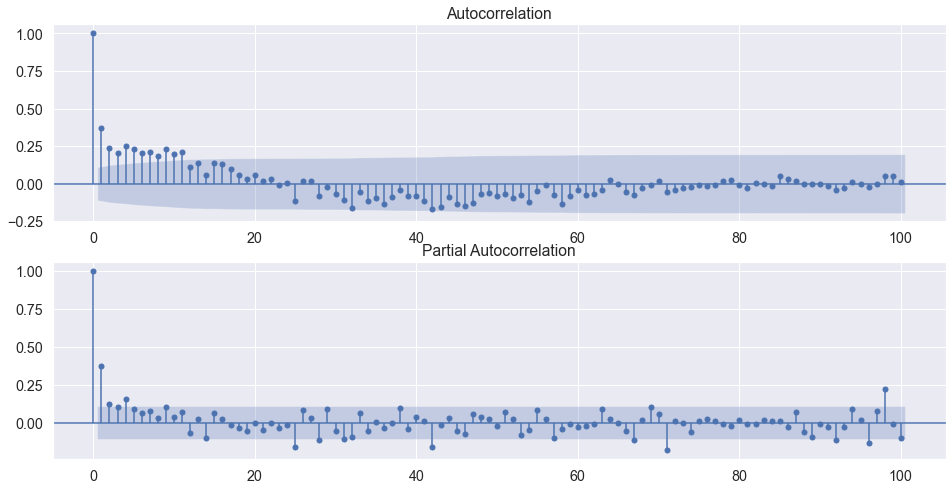

In [18]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.tsaplots import plot_pacf

f, ax = plt.subplots(nrows=2, ncols=1, figsize=(16, 8))

plot_acf(df_part3['sentiment'], lags=100, ax=ax[0])
plot_pacf(df_part3['sentiment'], lags=100, ax=ax[1])

plt.show()

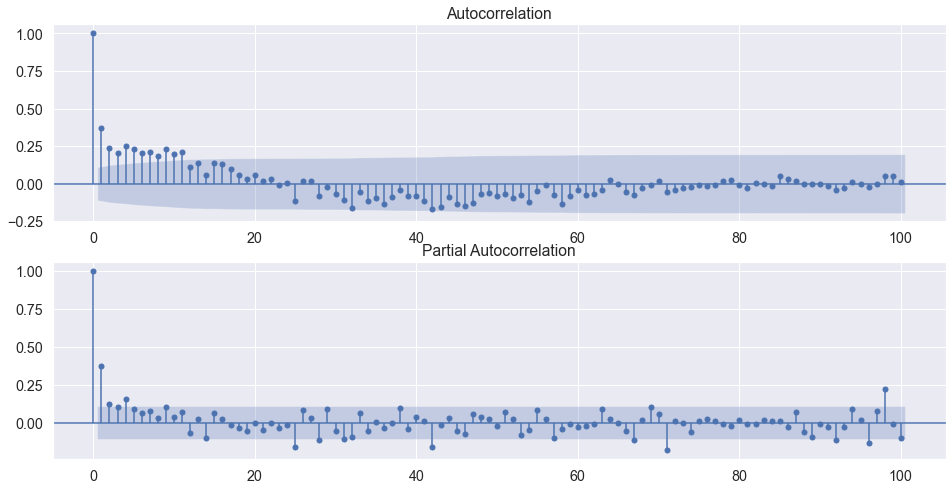

In [19]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.tsaplots import plot_pacf

f, ax = plt.subplots(nrows=2, ncols=1, figsize=(16, 8))

plot_acf(df_part3['sentiment'], lags=100, ax=ax[0])
plot_pacf(df_part3['sentiment'], lags=100, ax=ax[1])

plt.show()

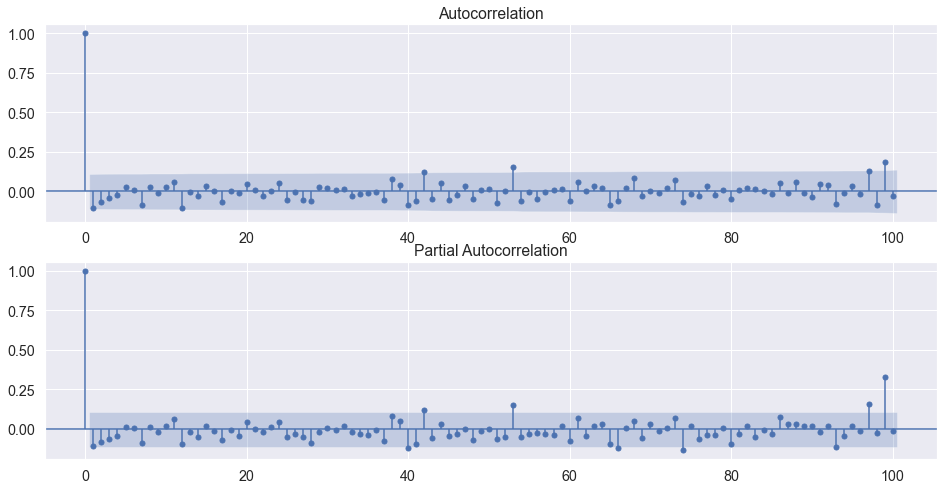

In [20]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.tsaplots import plot_pacf

f, ax = plt.subplots(nrows=2, ncols=1, figsize=(16, 8))

plot_acf(df_part3['vix_ln_return'], lags=100, ax=ax[0])
plot_pacf(df_part3['vix_ln_return'], lags=100, ax=ax[1])

plt.show()

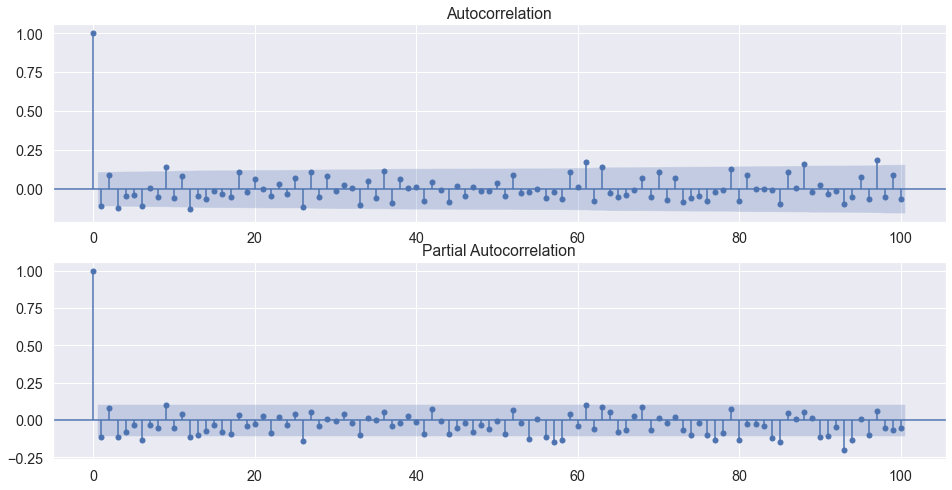

In [21]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.tsaplots import plot_pacf

f, ax = plt.subplots(nrows=2, ncols=1, figsize=(16, 8))

plot_acf(df_part3['sp500_ln_return'], lags=100, ax=ax[0])
plot_pacf(df_part3['sp500_ln_return'], lags=100, ax=ax[1])

plt.show()

In [22]:

%matplotlib inline
from pylab import rcParams
from plotly import tools
from plotly.offline import init_notebook_mode, iplot
init_notebook_mode(connected=True)
import plotly.graph_objs as go
import plotly.figure_factory as ff
import statsmodels.api as sm
from numpy.random import normal, seed
from scipy.stats import norm
from statsmodels.tsa.arima_model import ARMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.tsa.arima_model import ARIMA
import math
from sklearn.metrics import mean_squared_error

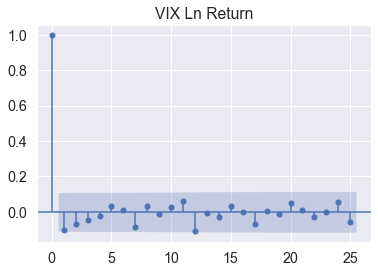

In [23]:
plot_acf(df_part3["vix_ln_return"],lags=25,title="VIX Ln Return")
plt.show()

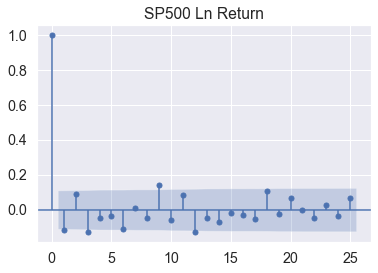

In [24]:
plot_acf(df_part3.sp500_ln_return[0:],lags=25,title="SP500 Ln Return")
plt.show()

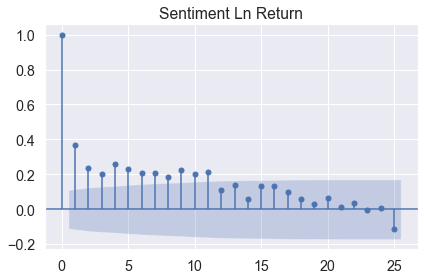

In [25]:
plot_acf(df_part3.sentiment[1:],lags=25,title="Sentiment Ln Return")

plt.tight_layout()

plt.show()

# Partial Autocorrelation

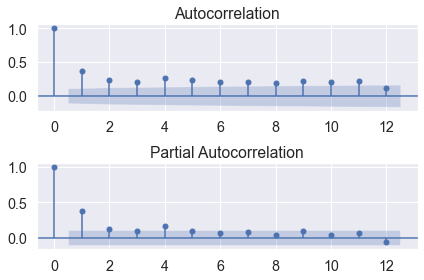

In [26]:
# Initial approximation of parameters using Autocorrelation and Partial Autocorrelation Plots
ax = plt.subplot(211)
# Plot the autocorrelation function
#sm.graphics.tsa.plot_acf(btc_month.box_diff2[13:].values.squeeze(), lags=48, ax=ax)
plot_acf(df_part3.sentiment[1:].values.squeeze(), lags=12, ax=ax)
ax = plt.subplot(212)
#sm.graphics.tsa.plot_pacf(btc_month.box_diff2[13:].values.squeeze(), lags=48, ax=ax)
plot_pacf(df_part3.sentiment[1:].values.squeeze(), lags=12, ax=ax)
plt.tight_layout()

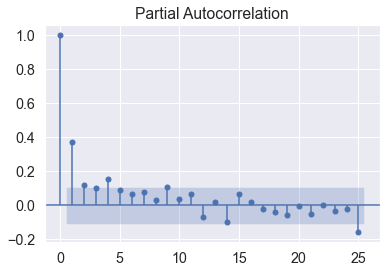

In [27]:
plot_pacf(df_part3["sentiment"],lags=25)
plt.show()

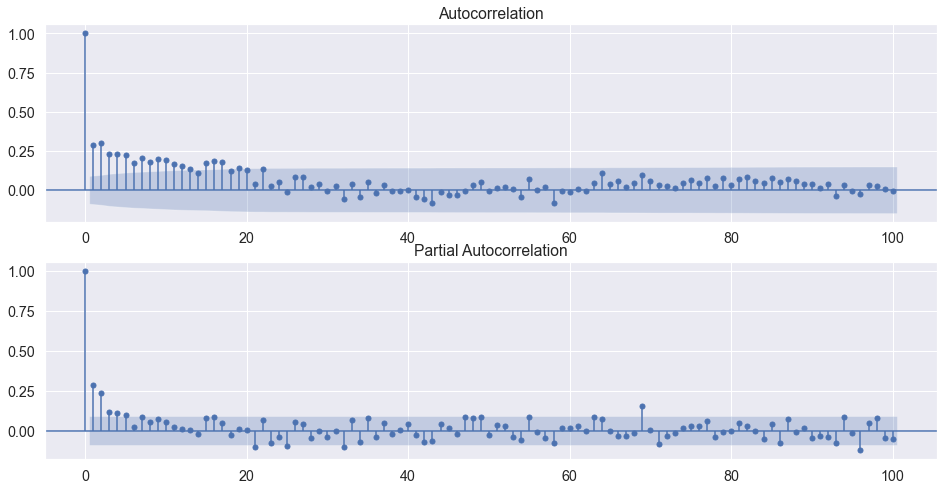

In [28]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.tsaplots import plot_pacf

f, ax = plt.subplots(nrows=2, ncols=1, figsize=(16, 8))

plot_acf(df['sentiment'], lags=100, ax=ax[0])
plot_pacf(df['sentiment'], lags=100, ax=ax[1])

plt.show()

In [29]:
train_size = int(0.85 * len(df))
test_size = len(df) - train_size

univariate_df = df[['Date', 'sentiment']].copy()
univariate_df.columns = ['ds', 'y']

train = univariate_df.iloc[:train_size, :]

x_train, y_train = pd.DataFrame(univariate_df.iloc[:train_size, 0]), pd.DataFrame(univariate_df.iloc[:train_size, 1])
x_valid, y_valid = pd.DataFrame(univariate_df.iloc[train_size:, 0]), pd.DataFrame(univariate_df.iloc[train_size:, 1])

print(len(train), len(x_valid))

414 74


[]

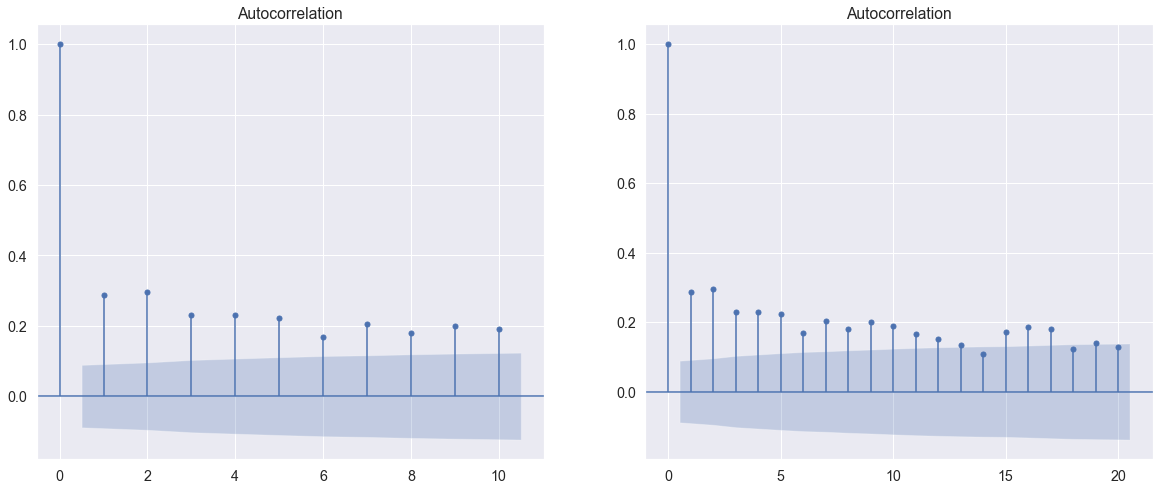

In [30]:
#isolate the original series of demand data
sentiment = df['sentiment']

fig, axs = plt.subplots(1,2, figsize=(20,8))

#we will plot the last 30 and 90 days
lags = [10, 20]

for ax, lag in zip(axs.flatten(), lags):
    plot_acf(sentiment, ax=ax, lags=lag)
plt.plot()

In [31]:
# plots = len(day_energy.columns)
# fig, axs = plt.subplots(int(plots/2), 2, figsize=(15, 2*plots))

# for hour, ax in zip(day_energy.columns, axs.flatten()):
#         plot_pacf(day_energy.loc[:,hour], ax=ax, lags=60)
#         ax.set_title('Partial Autocorrelation hour ' + str(hour))
# plt.plot()

AttributeError: 'numpy.ndarray' object has no attribute 'figure'

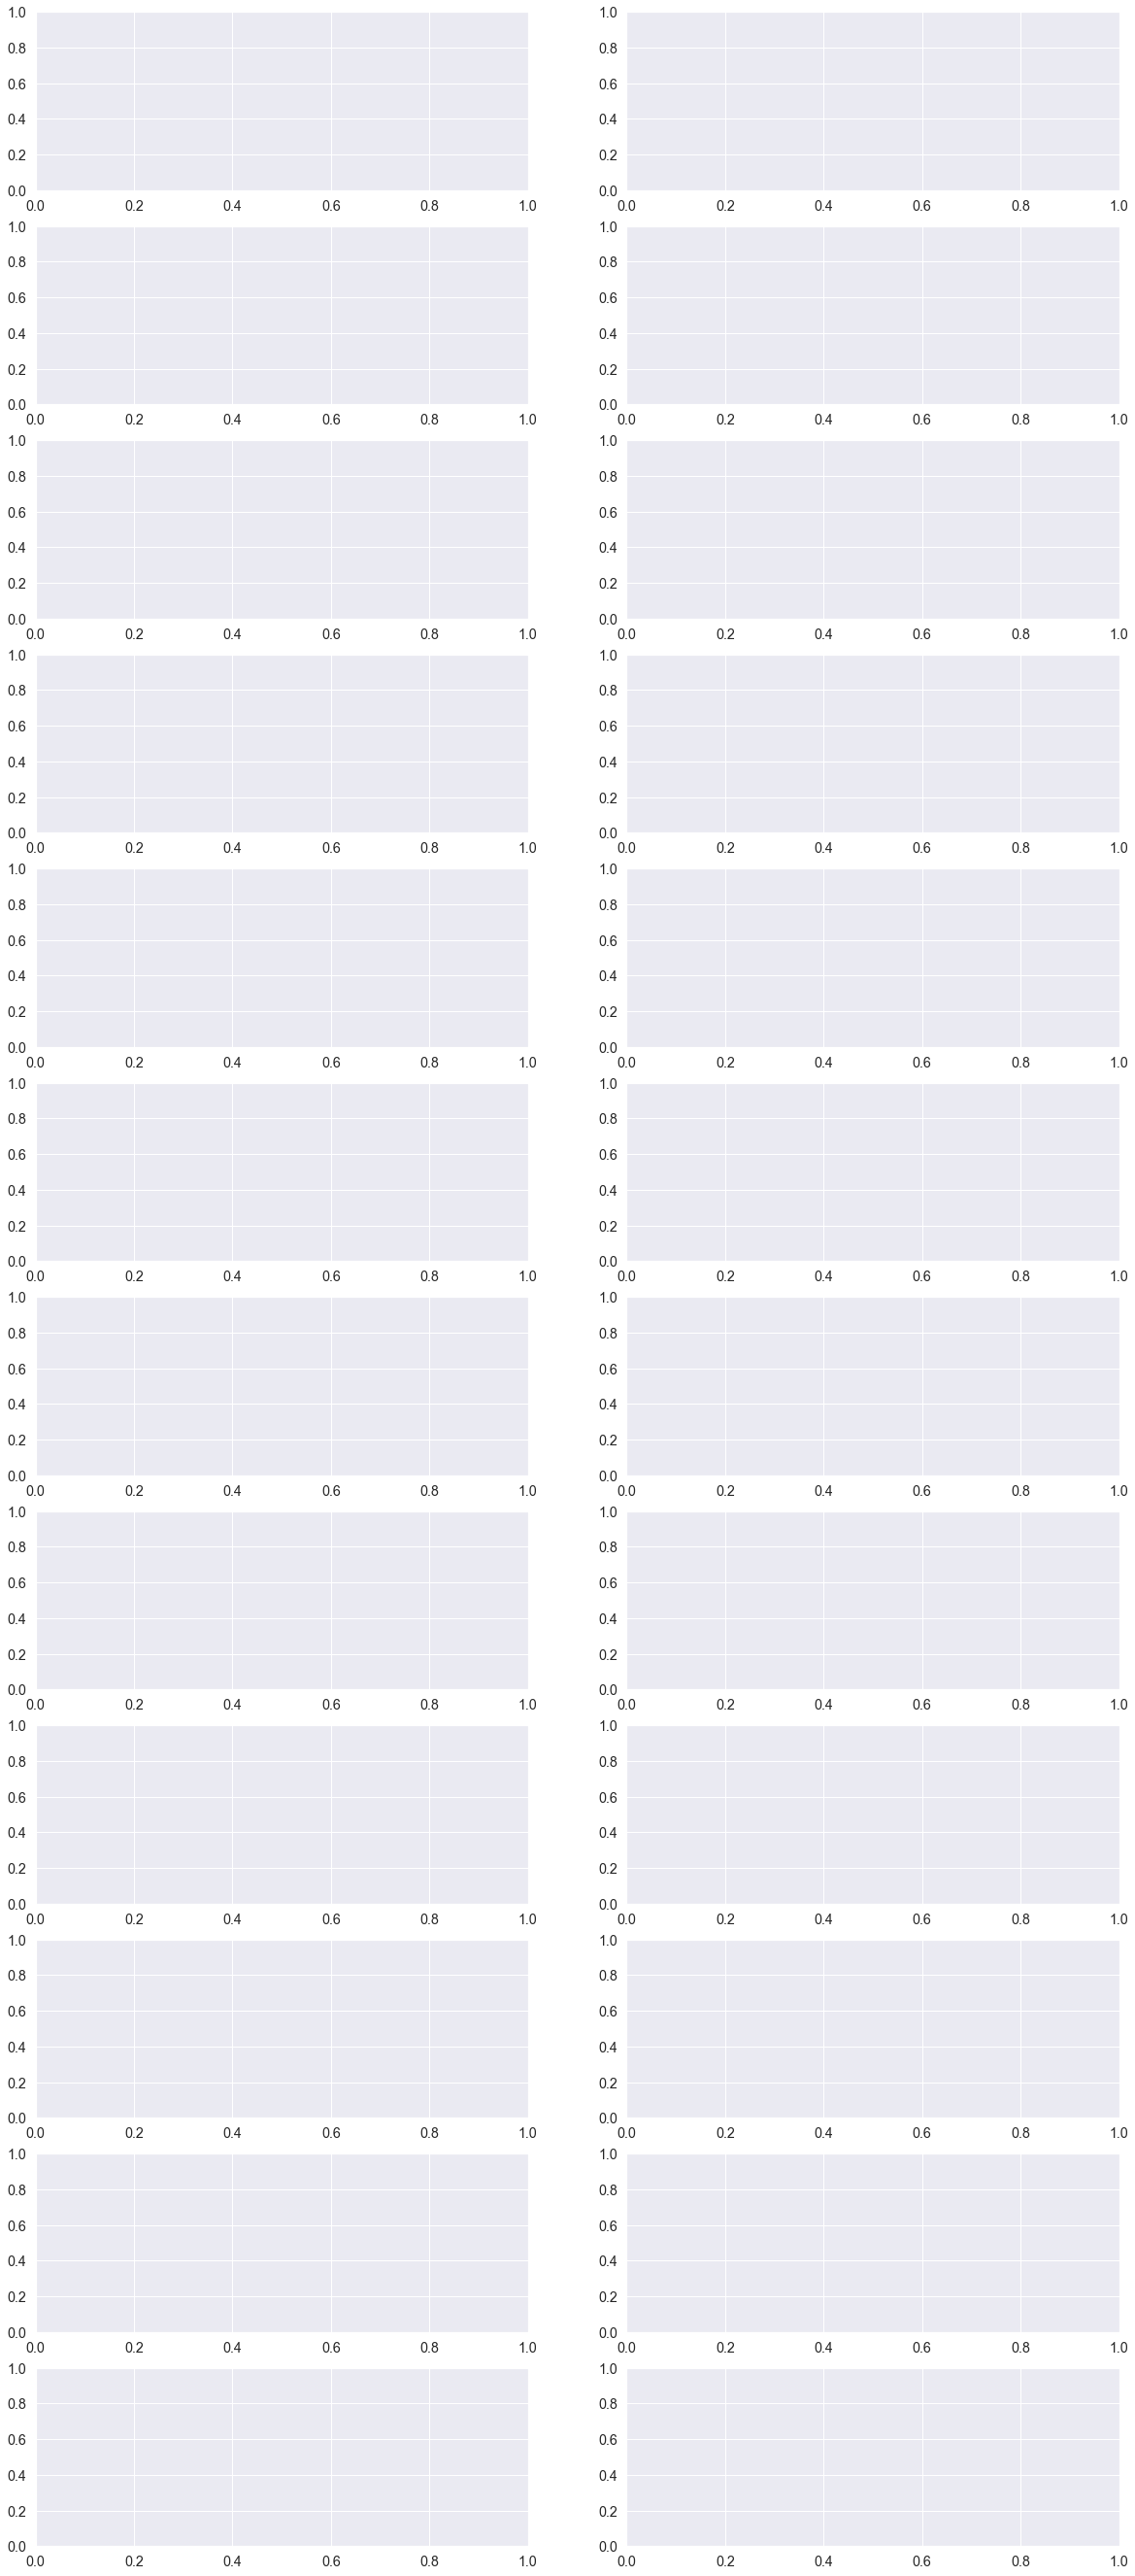

In [32]:
#isolate the original series of demand data

# fig, axs = plt.subplots(1,2, figsize=(20,8))

# #we will plot the last 30 and 90 days
# lags = [10, 20]

# for ax, lag in zip(axs.flatten(), lags):



#we will plot the last 30 and 90 days
lags = [10, 20]
fig, axs = plt.subplots(12,2, figsize=(20,48))

for hour in range(0,23):
    hourly = df_hour_part3.loc[df_hour_part3["Hour"]==1]
    sentiment = pd.DataFrame(data=hourly['sentiment'])
    for ax, lag in zip(axs[hour].flatten(), lags):
        plot_acf( sentiment, ax=axs[hour], lags=lag)
        axs[hour].set_title('Partial Autocorrelation hour ' + str(hour))
plt.plot()

# Lag Plots
## A Lag plot is a scatter plot of a time series against a lag of itself. It is normally used to check for autocorrelation. If there is any pattern existing in the series, the series is autocorrelated. If there is no such pattern, the series is likely to be random white noise.

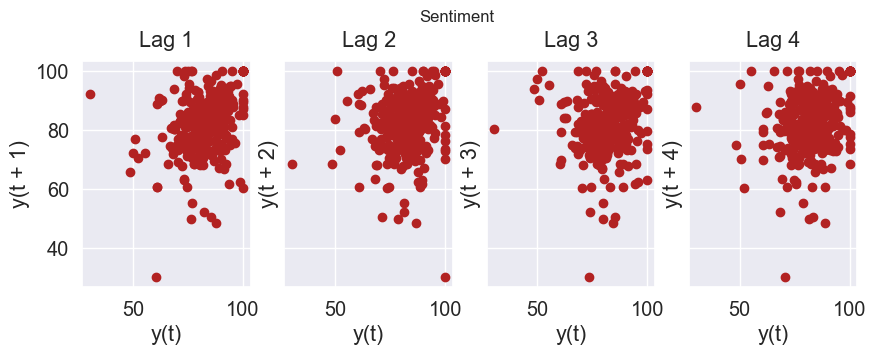

In [33]:
from pandas.plotting import lag_plot
plt.rcParams.update({'ytick.left' : False, 'axes.titlepad':10})

# Plot
fig, axes = plt.subplots(1, 4, figsize=(10,3), sharex=True, sharey=True, dpi=100)
for i, ax in enumerate(axes.flatten()[:4]):
    lag_plot(df_part3['sentiment'], lag=i+1, ax=ax, c='firebrick')
    ax.set_title('Lag ' + str(i+1))

fig.suptitle('Sentiment', y=1.05)    
plt.show()